# Huffman Coding

## 1. Introduction

Huffman Coding is a lossless data compression algorithm developed by David A. Huffman in 1952.

It reduces the size of data by assigning shorter binary codes to frequently occurring symbols and longer binary codes to less frequent symbols.

Unlike fixed-length encoding, where every symbol uses the same number of bits, Huffman Coding uses variable-length codes.

### Objectives

In this notebook, we will:

- Understand the principles behind Huffman Coding.
- Build a Huffman Tree based on symbol frequencies.
- Generate unique binary codes for each symbol.
- Implement encoding and decoding.
- Compress and decompress actual files.
- Evaluate compression ratios and performance.

### Implementation Approach

We will implement Huffman Coding using Python and operate directly on bytes rather than characters.

This allows our implementation to support both text and binary files.



## 2. Theoretical Background

### 2.1 Why Compression?

Data compression reduces the number of bits required to represent information.

Consider the following example:

`AAAAABBCD`

The symbol `A` occurs five times, while `B` occurs twice and `C` and `D` occur once each.

Using standard ASCII encoding, every character requires 8 bits.

However, we can reduce the total number of bits by assigning shorter codes to frequent symbols.

### 2.2 Variable-Length Encoding

Huffman Coding assigns binary codes according to symbol frequency.

The more frequently a symbol appears, the shorter its assigned code tends to be.

An important property is that Huffman codes are **prefix-free**.

This means that no symbol's code is the prefix of another symbol's code.

For example:

| Symbol | Code |
|---|---|
| A | 0 |
| B | 10 |
| C | 110 |
| D | 111 |

Because of the prefix-free property, encoded data can be decoded unambiguously without requiring separators between codes.

### 2.3 The Huffman Tree

Huffman Coding constructs a binary tree using the following process:

1. Calculate the frequency of every symbol.
2. Create a leaf node for each unique symbol.
3. Insert all nodes into a priority queue.
4. Extract the two nodes with the smallest frequencies.
5. Combine them into a new parent node.
6. Insert the parent back into the priority queue.
7. Repeat until only one node remains.

The remaining node is the root of the Huffman Tree.

Each left edge represents `0`, and each right edge represents `1`.

The path from the root to a leaf determines that symbol's Huffman code.

### 2.4 Important Properties

- Lossless: decompression reconstructs the original data exactly.
- Prefix-free: codes can be decoded without ambiguity.
- Frequency-based: code lengths depend on symbol frequencies.
- Variable-length: symbols can have different code lengths.

**Note:** Huffman Coding does not always reduce file size. Random data with nearly uniform symbol frequencies may not compress effectively, and storing the decoding information introduces additional overhead.


In [ ]:
from collections import Counter # Calculates symbol frequencies.
import heapq # Implements the priority queue used to build the tree.
from dataclasses import dataclass # Defines our Huffman tree nodes.
from pathlib import Path # Handles file system paths.
import math # Provides mathematical functions like ceil and log2.
import time # Measures the time taken to compress and decompress files.


## 3. Frequency Analysis

The first step in Huffman Coding is calculating the frequency of every unique symbol in the input data.

A symbol's frequency represents the number of times it appears in the input.

Since our implementation operates on bytes, each symbol is an integer between 0 and 255.

For example, consider the input:

`AAAAABBCD`

The frequencies are:

| Symbol | Frequency |
|---|---:|
| A | 5 |
| B | 2 |
| C | 1 |
| D | 1 |

These frequencies determine the priority of symbols when constructing the Huffman Tree.

Symbols with smaller frequencies will generally receive longer codes, while symbols with higher frequencies will receive shorter codes.

We will use Python's `Counter` class to calculate these frequencies efficiently.


In [2]:
def calculate_frequencies(data: bytes) -> Counter:
    """
    Calculate the frequency of each byte in the input data.

    Args:
        data: Input data represented as bytes.

    Returns:
        A Counter mapping each byte to its frequency.
    """
    return Counter(data)

In [3]:
sample_data = b"AAAAABBCD"

frequencies = calculate_frequencies(sample_data)

for symbol, frequency in sorted(frequencies.items()):
    print(f"Symbol: {chr(symbol)} | Byte: {symbol} | Frequency: {frequency}")

Symbol: A | Byte: 65 | Frequency: 5
Symbol: B | Byte: 66 | Frequency: 2
Symbol: C | Byte: 67 | Frequency: 1
Symbol: D | Byte: 68 | Frequency: 1



### 3.1 Understanding the Frequency Distribution

The previous example contains four unique symbols and nine total symbols.

Their frequencies are:

- A: 5 occurrences
- B: 2 occurrences
- C: 1 occurrence
- D: 1 occurrence

The sum of all frequencies must equal the total number of bytes in the input.

This gives us an important correctness condition:

\[
\sum_{b \in B} f(b) = |data|
\]

Where:

- \(B\) is the set of unique bytes.
- \(f(b)\) is the frequency of byte \(b\).
- \(|data|\) is the total input size in bytes.

We can use this property to validate our frequency calculation.



## 4. Building the Huffman Tree

After calculating symbol frequencies, we need to construct a binary tree that determines the code assigned to each symbol.

We use a **Min-Heap (Priority Queue)** to efficiently retrieve the two nodes with the smallest frequencies.

### Algorithm

1. Create a leaf node for every unique symbol.
2. Insert all leaf nodes into a Min-Heap.
3. Extract the two nodes with the smallest frequencies.
4. Create a new internal node whose frequency is the sum of both nodes.
5. Make the extracted nodes its left and right children.
6. Insert the new node back into the heap.
7. Repeat until the heap contains exactly one node.

The remaining node represents the root of the Huffman Tree.

### Example

Consider the following frequencies:

| Symbol | Frequency |
|---|---:|
| A | 5 |
| B | 2 |
| C | 1 |
| D | 1 |

The construction process:

**Iteration 1**

Combine C (1) and D (1).

New node frequency = 2.

**Iteration 2**

Combine B (2) and the new node (2).

New node frequency = 4.

**Iteration 3**

Combine the node with frequency 4 and A (5).

New root frequency = 9.

The resulting tree contains all four symbols as leaves.

### Why a Min-Heap?

A Min-Heap allows us to retrieve the smallest-frequency node efficiently.

Both insertion and removal take \(O(\log n)\) time.

Building the complete Huffman Tree takes \(O(n \log n)\) time, where \(n\) is the number of unique symbols.


In [5]:
@dataclass
class HuffmanNode:
    frequency: int
    symbol: int | None = None
    left: "HuffmanNode | None" = None
    right: "HuffmanNode | None" = None

    @property
    def is_leaf(self) -> bool:
        return self.left is None and self.right is None


### 4.1 Constructing the Tree Using a Min-Heap

Python's `heapq` module provides a Min-Heap implementation.

However, our Huffman nodes are custom objects, so we need a way to determine their ordering.

We'll use tuples containing:

`(frequency, unique_id, node)`

The unique ID ensures that nodes with equal frequencies can still be ordered without Python attempting to compare the node objects themselves.

This is important because equal frequencies are common in Huffman Coding.

We will also use a monotonically increasing counter to make the ordering deterministic for a given insertion sequence.


In [7]:
def build_huffman_tree(frequencies: Counter) -> HuffmanNode | None:
    """
    Build a Huffman Tree from symbol frequencies.

    Args:
        frequencies: Mapping of byte values to their frequencies.

    Returns:
        Root node of the Huffman Tree, or None for empty input.
    """
    if not frequencies:
        return None

    heap = []
    unique_id = 0

    # Create one leaf node for every unique symbol.
    for symbol, frequency in sorted(frequencies.items()):
        node = HuffmanNode(
            frequency=frequency,
            symbol=symbol
        )

        heapq.heappush(heap, (frequency, unique_id, node))
        unique_id += 1

    # Repeatedly combine the two smallest nodes.
    while len(heap) > 1:
        freq1, _, left = heapq.heappop(heap)
        freq2, _, right = heapq.heappop(heap)

        merged_node = HuffmanNode(
            frequency=freq1 + freq2,
            left=left,
            right=right
        )

        heapq.heappush(
            heap,
            (merged_node.frequency, unique_id, merged_node)
        )

        unique_id += 1

    return heap[0][2]

In [8]:
root = build_huffman_tree(frequencies)

print("Root frequency:", root.frequency)
print("Is root a leaf?", root.is_leaf)

Root frequency: 9
Is root a leaf? False



### 4.2 Visualizing the Huffman Tree with Matplotlib

We will use Matplotlib to visualize the actual structure of the Huffman Tree.

The visualization follows these conventions:

- Internal nodes display their combined frequency.
- Leaf nodes display their corresponding symbols and frequencies.
- Left edges are labeled `0`.
- Right edges are labeled `1`.
- Internal nodes and leaf nodes have different visual styles.

The horizontal position of each node is determined by its descendants, while its vertical position represents its depth in the tree.

This makes it easier to understand how the tree is constructed and how each symbol's binary code is derived from its path.


In [12]:
import matplotlib.pyplot as plt

In [18]:

def visualize_huffman_tree(root: HuffmanNode | None, title="Huffman Tree"):
    """
    Draw a complete Huffman Tree with automatically calculated positions.
    """

    if root is None:
        print("Cannot visualize an empty tree.")
        return

    positions = {}
    edges = []
    leaf_positions = []
    max_depth = 0

    # Calculate positions using leaf ordering.
    def layout(node, depth=0):
        nonlocal max_depth
        max_depth = max(max_depth, depth)

        if node.is_leaf:
            x = len(leaf_positions)
            leaf_positions.append(x)
        else:
            left_x = layout(node.left, depth + 1)
            right_x = layout(node.right, depth + 1)
            x = (left_x + right_x) / 2

        positions[id(node)] = (x, -depth)
        return x

    layout(root)

    # Collect edges.
    def collect_edges(node):
        if node.left:
            edges.append((node, node.left, "0"))
            collect_edges(node.left)

        if node.right:
            edges.append((node, node.right, "1"))
            collect_edges(node.right)

    collect_edges(root)

    leaf_count = len(leaf_positions)

    # Dynamic figure dimensions.
    fig, ax = plt.subplots(
        figsize=(
            max(10, leaf_count * 2.2),
            max(5, max_depth * 2.2 + 2)
        )
    )

    # Draw connections.
    for parent, child, bit in edges:
        x1, y1 = positions[id(parent)]
        x2, y2 = positions[id(child)]

        ax.plot(
            [x1, x2],
            [y1, y2],
            color="gray",
            linewidth=2,
            zorder=1
        )

        # Edge labels.
        mid_x = (x1 + x2) / 2
        mid_y = (y1 + y2) / 2

        ax.text(
            mid_x,
            mid_y,
            bit,
            fontsize=12,
            fontweight="bold",
            ha="center",
            va="center",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 3
            },
            zorder=3
        )

    # Draw nodes.
    def draw_nodes(node):
        x, y = positions[id(node)]

        if node.is_leaf:
            symbol = node.symbol

            if 32 <= symbol <= 126:
                symbol_label = repr(chr(symbol))
            else:
                symbol_label = f"0x{symbol:02X}"

            label = f"{symbol_label}\n {node.frequency}"
            node_color = "lightgreen"
        else:
            label = f"{node.frequency}"
            node_color = "lightblue"

        ax.scatter(
            x,
            y,
            s=1900,
            color=node_color,
            edgecolors="black",
            linewidths=1.8,
            zorder=2
        )

        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            zorder=4
        )

        if node.left:
            draw_nodes(node.left)

        if node.right:
            draw_nodes(node.right)

    draw_nodes(root)

    # Configure the plot.
    ax.set_title(title, fontsize=17, fontweight="bold", pad=25)

    # IMPORTANT: Use the actual tree depth, not the leaf count.
    ax.set_xlim(-0.8, max(leaf_count - 0.2, 0.8))
    ax.set_ylim(-max_depth - 0.8, 0.8)

    ax.axis("off")

    plt.tight_layout()
    plt.show()


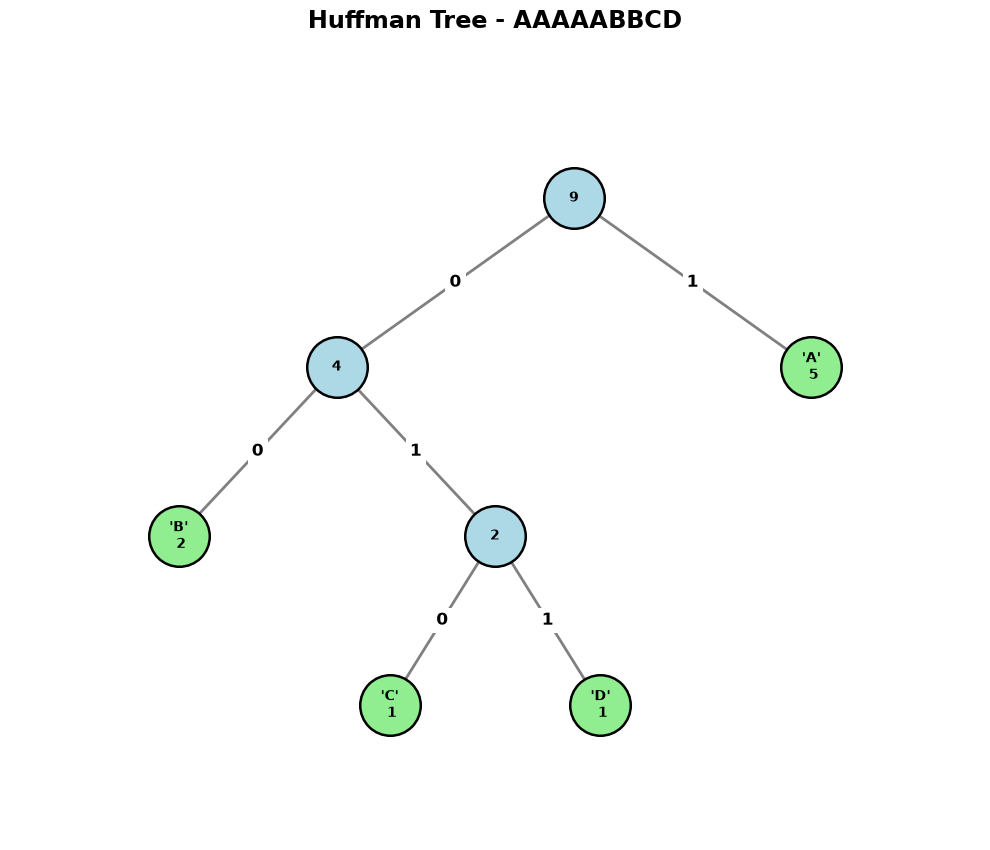

In [19]:
visualize_huffman_tree(
    root,
    title="Huffman Tree - AAAAABBCD"
)


## 5. Generating Huffman Codes

Once the Huffman Tree has been constructed, we can generate a binary code for every unique symbol.

### Traversal Rules

We start at the root and recursively traverse the tree:

1. When moving to the left child, append `0` to the current code.
2. When moving to the right child, append `1` to the current code.
3. When a leaf node is reached, save the accumulated code for that symbol.

The resulting mapping associates every symbol with its Huffman code.

### Example

For the input `AAAAABBCD`, one possible Huffman code assignment is:

| Symbol | Frequency | Huffman Code |
|---|---:|---|
| A | 5 | 1 |
| B | 2 | 00 |
| C | 1 | 010 |
| D | 1 | 011 |

The exact codes depend on the tree's tie-breaking decisions.

### Single-Symbol Input

An important special case occurs when the input contains only one unique symbol.

For example, `AAAAAA` produces a tree containing only one leaf.

Since there are no edges to traverse, we assign the code `0` to that symbol.

This ensures that every encoded symbol has at least one bit.


In [20]:
def generate_huffman_codes(root: HuffmanNode | None) -> dict[int, str]:
    """
    Generate binary Huffman codes by traversing the tree.

    Returns:
        Dictionary mapping each byte value to its binary code.
    """
    codes = {}

    if root is None:
        return codes

    def traverse(node, current_code):
        if node.is_leaf:
            # A single-symbol tree needs at least one bit.
            codes[node.symbol] = current_code or "0"
            return

        traverse(node.left, current_code + "0")
        traverse(node.right, current_code + "1")

    traverse(root, "")

    return codes

In [21]:
huffman_codes = generate_huffman_codes(root)

print("Symbol | Frequency | Huffman Code")
print("-" * 40)

for symbol, code in sorted(huffman_codes.items()):
    print(
        f"{chr(symbol)!r:6} | "
        f"{frequencies[symbol]:9} | "
        f"{code}"
    )

Symbol | Frequency | Huffman Code
----------------------------------------
'A'    |         5 | 1
'B'    |         2 | 00
'C'    |         1 | 010
'D'    |         1 | 011



### 5.1 Verifying the Prefix-Free Property

A valid Huffman code must be prefix-free.

A code is prefix-free when no code is the beginning of another code.

For example:

- `0` and `10` are prefix-free.
- `10` and `101` are not prefix-free because `10` is a prefix of `101`.

Why is this important?

Consider the encoded sequence:

`001011`

With prefix-free codes, the decoder can determine where each symbol's code ends without needing separators.

This makes unambiguous decoding possible.


In [22]:
def is_prefix_free(codes: dict[int, str]) -> bool:
    """
    Check whether a collection of binary codes is prefix-free.
    """
    code_list = list(codes.values())

    for i, code in enumerate(code_list):
        for j, other_code in enumerate(code_list):
            if i != j and other_code.startswith(code):
                return False

    return True

In [26]:
assert is_prefix_free(huffman_codes)

print("Prefix-free validation passed!")

Prefix-free validation passed!


In [24]:
import pandas as pd

code_table = pd.DataFrame([
    {
        "Symbol": repr(chr(symbol)) if 32 <= symbol <= 126 else f"0x{symbol:02X}",
        "Byte": symbol,
        "Frequency": frequencies[symbol],
        "Huffman Code": code,
        "Code Length": len(code)
    }
    for symbol, code in sorted(huffman_codes.items())
])

display(code_table)

,Symbol,Byte,Frequency,Huffman Code,Code Length
0,'A',65,5,1,1
1,'B',66,2,00,2
2,'C',67,1,010,3
3,'D',68,1,011,3


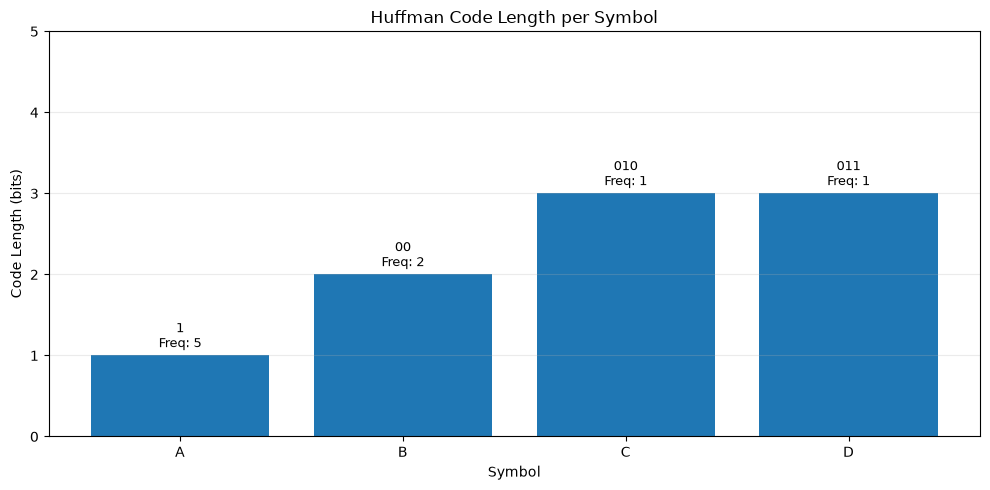

In [25]:
def visualize_code_lengths(frequencies, codes):
    symbols = sorted(codes)

    labels = [
        chr(s) if 32 <= s <= 126 else f"0x{s:02X}"
        for s in symbols
    ]

    lengths = [len(codes[s]) for s in symbols]
    counts = [frequencies[s] for s in symbols]

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(labels, lengths)

    for bar, frequency, code in zip(bars, counts, [codes[s] for s in symbols]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{code}\nFreq: {frequency}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title("Huffman Code Length per Symbol")
    ax.set_xlabel("Symbol")
    ax.set_ylabel("Code Length (bits)")
    ax.set_ylim(0, max(lengths) + 2)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


visualize_code_lengths(frequencies, huffman_codes)


## 6. Huffman Encoding

Encoding converts the original input data into a sequence of Huffman bits.

For every byte in the original input:

1. Look up its Huffman code.
2. Append the code to the encoded bit sequence.
3. Group the bits into chunks of 8.
4. Convert each group into a byte.
5. Handle any remaining bits using padding.

### 6.1 Bit Packing

Computers store data in bytes, where each byte contains 8 bits.

However, the total number of Huffman bits may not be divisible by 8.

For example:

`10110110101`

This sequence contains 11 bits.

We can split it into:

`10110110 101`

The final group contains only 3 bits.

We append five zero bits to complete the byte:

`10110110 10100000`

The resulting output contains two bytes.

**Important:** Padding bits are not part of the original encoded sequence. We must preserve the original bit length so that the decoder knows exactly where the meaningful data ends.



### 6.2 Implementing the Encoder

We will implement a bit accumulator instead of storing the entire encoded sequence as a string.

The accumulator:

- Shifts the current byte left by one position.
- Inserts the next encoded bit.
- Counts how many bits have been collected.
- Writes a byte whenever 8 bits have accumulated.

This avoids creating a potentially enormous intermediate bit string.

The encoder returns two values:

- `encoded_bytes`: the packed compressed data.
- `bit_length`: the number of meaningful bits before padding.

The bit length is essential for correct decoding.


In [27]:

def encode_data(
    data: bytes,
    codes: dict[int, str]
) -> tuple[bytes, int]:
    """
    Encode input bytes using Huffman codes and pack the bits into bytes.

    Returns:
        A tuple containing:
        - Packed encoded bytes.
        - Number of meaningful bits before padding.
    """
    if not data:
        return b"", 0

    output = bytearray()
    current_byte = 0
    bits_filled = 0
    total_bits = 0

    for symbol in data:
        if symbol not in codes:
            raise ValueError(
                f"No Huffman code found for byte: {symbol}"
            )

        code = codes[symbol]

        for bit in code:
            current_byte = (current_byte << 1) | int(bit)

            bits_filled += 1
            total_bits += 1

            if bits_filled == 8:
                output.append(current_byte)

                current_byte = 0
                bits_filled = 0

    # Pad the final incomplete byte with zeros.
    if bits_filled > 0:
        current_byte <<= (8 - bits_filled)
        output.append(current_byte)

    return bytes(output), total_bits


In [28]:
encoded_bytes, encoded_bit_length = encode_data(
    sample_data,
    huffman_codes
)

print("Original data:", sample_data)
print("Original size:", len(sample_data), "bytes")

print("\nEncoded bytes:", encoded_bytes)
print("Encoded hexadecimal:", encoded_bytes.hex(" "))

print("Meaningful encoded bits:", encoded_bit_length)
print("Encoded storage size:", len(encoded_bytes), "bytes")

Original data: b'AAAAABBCD'
Original size: 9 bytes

Encoded bytes: b'\xf8&'
Encoded hexadecimal: f8 26
Meaningful encoded bits: 15
Encoded storage size: 2 bytes



### 6.3 Inspecting the Packed Binary Data

To understand how bit packing works, we can convert the resulting bytes back into their binary representation.

Remember that the final byte may contain padding zeros.

We will display both the complete stored bits and the meaningful bits separately.

This helps us distinguish the actual Huffman encoding from the additional padding required to store it in complete bytes.


In [29]:
def display_encoded_bits(
    encoded_bytes: bytes,
    bit_length: int
) -> None:
    """
    Display packed bytes as binary and distinguish padding bits.
    """
    if not encoded_bytes:
        print("No encoded data.")
        return

    all_bits = "".join(
        format(byte, "08b")
        for byte in encoded_bytes
    )

    meaningful_bits = all_bits[:bit_length]
    padding_bits = all_bits[bit_length:]

    print("Stored bits:     ", all_bits)
    print("Meaningful bits: ", meaningful_bits)
    print("Padding bits:    ", padding_bits or "None")


display_encoded_bits(encoded_bytes, encoded_bit_length)

Stored bits:      1111100000100110
Meaningful bits:  111110000010011
Padding bits:     0


In [30]:
assert encoded_bit_length == sum(
    frequencies[symbol] * len(huffman_codes[symbol])
    for symbol in frequencies
)

assert len(encoded_bytes) == math.ceil(encoded_bit_length / 8)

assert encoded_bit_length <= len(encoded_bytes) * 8

print("Encoding validation passed!")

Encoding validation passed!



### 6.4 Handling Edge Cases

Before moving to decoding, we should consider two special inputs.

**Empty input**

An empty input must produce:
- Empty encoded bytes.
- Zero meaningful bits.

**Single-symbol input**

An input containing only one unique symbol receives the code `0`.

For example:

`AAAAAA`

Its encoded representation is:

`000000`

This requires 6 meaningful bits, stored in one byte with 2 padding bits.

These cases are important because a compression algorithm should work correctly beyond ordinary examples.


In [31]:
# Empty input
empty_encoded, empty_length = encode_data(b"", {})

assert empty_encoded == b""
assert empty_length == 0


# Single-symbol input
single_data = b"AAAAAA"

single_frequencies = calculate_frequencies(single_data)
single_root = build_huffman_tree(single_frequencies)
single_codes = generate_huffman_codes(single_root)

single_encoded, single_length = encode_data(
    single_data,
    single_codes
)

assert single_codes == {65: "0"}
assert single_length == 6
assert len(single_encoded) == 1

print("Empty input validation passed!")
print("Single-symbol validation passed!")

Empty input validation passed!
Single-symbol validation passed!
